<div class="alert alert-block alert-info">

- We computed the context vectors for each input words as Weighted sum over the Normalized Attention weights with Input Vectors
- Now , we will introduce weights that are trainable parameters and are updated during Model Training
- We will introduce 3 trainable weight matrices = Wq , Wk , Wv (Query , Key and Value vectors and weights)

- Wq , Wk , Wv - These three matrices are used to project the embedded Input tokens/words into corresponding Query , Key and Value vectors
- Inputs = 6 x 3 matrix , containing a 3dim vector embedding for each input
- Wq , Wk , Wv = 3 x 2 weight matrix [Initalized with random values and updated during Training]

- Q { query vectors for each i/p vectors } = Inputs @ Wq = 6 x 2 Resultant matrix - containing 6 query vectors of dim = 2 each 
- K { key vectors for each i/p vectors } = Inputs @ Wk = 6 x 2 Resultant matrix - containing 6 key vectors of dim = 2 each 
- V { va;ue vectors for each i/p vectors } = Inputs @ Wv = 6 x 2 Resultant matrix - containing 6 value vectors of dim = 2 each 
</div>

In [25]:
import torch

inputs = torch.tensor(
    [
        [0.43, 0.15, 0.89],  # Your     (x^1)
        [0.55, 0.87, 0.66],  # journey  (x^2)
        [0.57, 0.85, 0.64],  # starts   (x^3)
        [0.22, 0.58, 0.33],  # with     (x^4)
        [0.77, 0.25, 0.10],  # one      (x^5)
        [0.05, 0.80, 0.55],
    ]  # step     (x^6)
)

print("Input Shape:", inputs.shape)


Input Shape: torch.Size([6, 3])


In [26]:
# Input size = 3
d_in = inputs.shape[1]
# Output size of Wq , Wk, Wv weight matrices
d_out = 2

torch.manual_seed(123)

W_query = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_key = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_value = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)


In [27]:
print("W_query - 3x2 matrix :", W_query)
print("W_key - 3x2 matrix : ", W_key)
print("W_value -  3x2 matrix : ", W_value)


W_query - 3x2 matrix : Parameter containing:
tensor([[0.2961, 0.5166],
        [0.2517, 0.6886],
        [0.0740, 0.8665]])
W_key - 3x2 matrix :  Parameter containing:
tensor([[0.1366, 0.1025],
        [0.1841, 0.7264],
        [0.3153, 0.6871]])
W_value -  3x2 matrix :  Parameter containing:
tensor([[0.0756, 0.1966],
        [0.3164, 0.4017],
        [0.1186, 0.8274]])


<div class="alert alert-block alert-info">
    
Note that we are setting requires_grad=False to reduce clutter in the outputs for
illustration purposes. 

If we were to use the weight matrices for model training, we
would set requires_grad=True to update these matrices during model training.

</div>

In [28]:
keys = inputs @ W_key
values = inputs @ W_value
queries = inputs @ W_query

print("keys.shape:", keys.shape)
print("values.shape:", values.shape)
print("queries.shape:", queries.shape)


keys.shape: torch.Size([6, 2])
values.shape: torch.Size([6, 2])
queries.shape: torch.Size([6, 2])


In [29]:
# Computing the attention score for the second word in the input sequence (journey)

query_2 = queries[1]  # query for the second word (journey)
keys_2 = keys[1]  # keys for the second word (journey)

attn_Score_22 = query_2.dot(keys_2)  # dot product of query and key for the second word
print("Attention Score for the second word (journey):", attn_Score_22.item())


Attention Score for the second word (journey): 1.8523844480514526


In [30]:
# Again, we can generalize this computation to all attention scores (for all the key vectors with respect to query_2 vector) via matrix multiplication:

attn_scores_2 = query_2 @ keys.T

# All attention scores for given query
# (1x2) * (2*6) = (1*6) attention score (attention score of the second input(query vector in this case) with all other words in the inputs (key vectors))

print(attn_scores_2)


tensor([1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440])


In [31]:
all_attn_scores = queries @ keys.T  # omega
print(all_attn_scores)


tensor([[0.9231, 1.3545, 1.3241, 0.7910, 0.4032, 1.1330],
        [1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440],
        [1.2544, 1.8284, 1.7877, 1.0654, 0.5508, 1.5238],
        [0.6973, 1.0167, 0.9941, 0.5925, 0.3061, 0.8475],
        [0.6114, 0.8819, 0.8626, 0.5121, 0.2707, 0.7307],
        [0.8995, 1.3165, 1.2871, 0.7682, 0.3937, 1.0996]])


<div class="alert alert-block alert-success">
    
We compute the attention weights by scaling the
attention scores and using the softmax function we used earlier. 

The difference to earlier is
that we now scale the attention scores by dividing them by the square root of the
embedding dimension of the keys. 

Note that taking the square root is mathematically the
same as exponentiating by 0.5:</div>

In [32]:
d_k = keys.shape[-1]
attn_weights_2 = torch.softmax(attn_scores_2 / d_k**0.5, dim=-1)
print("Scaled and Normalized Attention weights : ", attn_weights_2)
print("Sum of attention weights : ", attn_weights_2.sum())
print("Dimension of key vector : ", d_k)


Scaled and Normalized Attention weights :  tensor([0.1500, 0.2264, 0.2199, 0.1311, 0.0906, 0.1820])
Sum of attention weights :  tensor(1.)
Dimension of key vector :  2


#### WHY DIVIDE BY SQRT (DIMENSION)

<div class="alert alert-block alert-warning">

Reason 1: For stability in learning

The softmax function is sensitive to the magnitudes of its inputs. When the inputs are large, the differences between the exponential values of each input become much more pronounced. This causes the softmax output to become "peaky," where the highest value receives almost all the probability mass, and the rest receive very little.

In attention mechanisms, particularly in transformers, if the dot products between query and key vectors become too large (like multiplying by 8 in this example), the attention scores can become very large. This results in a very sharp softmax distribution, making the model overly confident in one particular "key." Such sharp distributions can make learning unstable,
    
</div>

In [33]:
import torch

# Define the tensor
tensor = torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5])

# Apply softmax without scaling
softmax_result = torch.softmax(tensor, dim=-1)
print("Softmax without scaling : ", softmax_result)

# Multiply the tensor by 8 and then apply softmax
scaled_tensor = tensor * 8
softmax_scaled_result = torch.softmax(scaled_tensor, dim=-1)
print("Softmax after scaling (tensor * 8) : ", softmax_scaled_result)


Softmax without scaling :  tensor([0.1925, 0.1426, 0.2351, 0.1426, 0.2872])
Softmax after scaling (tensor * 8) :  tensor([0.0326, 0.0030, 0.1615, 0.0030, 0.8000])


<div class="alert alert-block alert-warning">

But why Square Root

Reason 2: To make the variance of the dot product stable

The dot product of  Q and K increases the variance because multiplying two random numbers increases the variance.

The increase in variance grows with the dimension. 

Dividing by sqrt (dimension) keeps the variance close to 1
    
</div>

In [34]:
import numpy as np


# Function to compute variance before and after scaling
def compute_variance(dim, num_trials=1000):
    dot_products = []
    scaled_dot_products = []

    # Generate multiple random vectors and compute dot products
    for _ in range(num_trials):
        q = np.random.randn(dim)
        k = np.random.randn(dim)

        # Compute dot product
        dot_product = np.dot(q, k)
        dot_products.append(dot_product)

        # Scale the dot product by sqrt(dim)
        scaled_dot_product = dot_product / np.sqrt(dim)
        scaled_dot_products.append(scaled_dot_product)

    # Calculate variance of the dot products
    variance_before_scaling = np.var(dot_products)
    variance_after_scaling = np.var(scaled_dot_products)

    return variance_before_scaling, variance_after_scaling


# For dimension 5
variance_before_5, variance_after_5 = compute_variance(5)
print(f"Variance before scaling (dim=5): {variance_before_5}")
print(f"Variance after scaling (dim=5): {variance_after_5}")

# For dimension 20
variance_before_100, variance_after_100 = compute_variance(100)
print(f"Variance before scaling (dim=100): {variance_before_100}")
print(f"Variance after scaling (dim=100): {variance_after_100}")


Variance before scaling (dim=5): 4.5316981636469995
Variance after scaling (dim=5): 0.9063396327293999
Variance before scaling (dim=100): 90.45736244744538
Variance after scaling (dim=100): 0.9045736244744539


In [35]:
context_vec_2 = attn_weights_2 @ values
print(context_vec_2)


tensor([0.3061, 0.8210])


#### IMPLEMENTING A COMPACT SELF ATTENTION PYTHON CLASS

<div class="alert alert-block alert-info">

nn.Linear has an optimized weight initialization scheme, contributing to more stable and effective model training Rather than using random weights, which can lead to unstable training and poor convergence. The nn.Linear layer initializes weights using a uniform distribution based on the number of input features, ensuring that the initial weights are neither too large nor too small. This helps in maintaining a balanced gradient flow during backpropagation, leading to better learning dynamics and improved model performance
    
</div>

In [36]:
import torch.nn as nn


class SelfAttention_v1(nn.Module):
    def __init__(self, d_in, d_out, qkv_bias=False):
        super().__init__()
        # self.W_query = nn.Parameter(torch.rand(d_in, d_out))
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        # self.W_key = nn.Parameter(torch.rand(d_in, d_out))
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        # self.W_value = nn.Parameter(torch.rand(d_in, d_out))
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

    def forward(self, x):
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)

        attn_scores = queries @ keys.T  # omega

        # Scale the attention scores by the square root of the dimension of the key vectors And Normalize the attention scores using softmax
        attn_weights = torch.softmax(attn_scores / keys.shape[-1] ** 0.5, dim=-1)

        context_vec = attn_weights @ values
        return context_vec


In [37]:
torch.manual_seed(123)
sa_v1 = SelfAttention_v1(d_in, d_out)
print(sa_v1(inputs))


tensor([[-0.5337, -0.1051],
        [-0.5323, -0.1080],
        [-0.5323, -0.1079],
        [-0.5297, -0.1076],
        [-0.5311, -0.1066],
        [-0.5299, -0.1081]], grad_fn=<MmBackward0>)


#### HIDING FUTURE WORDS WITH CAUSAL ATTENTION - MASKED SELF-ATTENTION

<div class="alert alert-block alert-info">
In causal attention, the attention weights above the diagonal are masked, ensuring that for any given input, the LLM is unable to utilize future tokens while calculating the context vectors with the attention weight
</div>

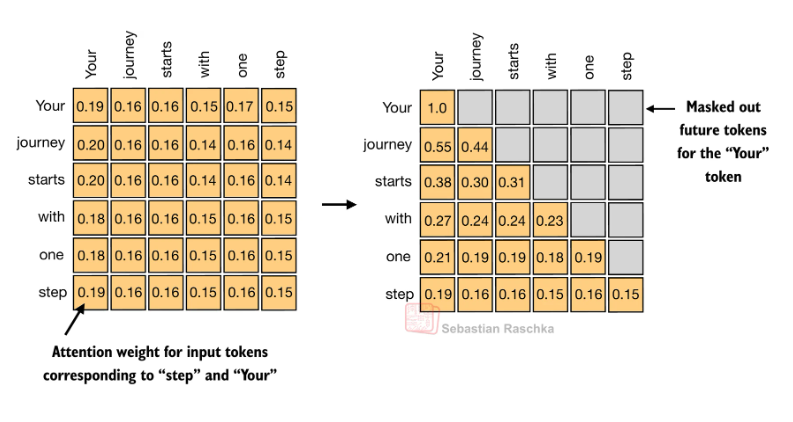

<div class="alert alert-block alert-info">

- Now We are converting the previous self-attention mechanism into a causal self-attention mechanism
- Causal self-attention ensures that the model's prediction for a certain position in a sequence is only dependent on the known outputs at previous positions, not on future positions
- In simpler words, this ensures that each next word prediction should only depend on the preceding words
- To achieve this, for each given token, we mask out the future tokens (the ones that come after the current token in the input text)
</div>

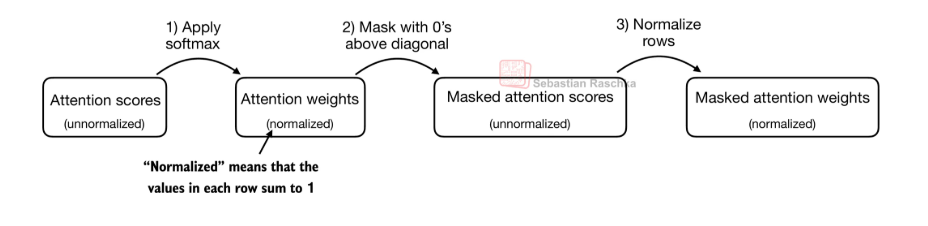


In [38]:
queries = sa_v1.W_query(inputs)
keys = sa_v1.W_key(inputs)
values = sa_v1.W_value(inputs)

attention_scores = queries @ keys.T
print("Attention Scores : ", attention_scores)

attention_weights = torch.softmax(attention_scores / keys.shape[-1] ** 0.5, dim=-1)
print("Attention Weights : ", attention_weights)


Attention Scores :  tensor([[0.3111, 0.3479, 0.3471, 0.1714, 0.2350, 0.1928],
        [0.1655, 0.2602, 0.2576, 0.1445, 0.1384, 0.1790],
        [0.1667, 0.2602, 0.2577, 0.1443, 0.1391, 0.1784],
        [0.0510, 0.1080, 0.1064, 0.0643, 0.0476, 0.0835],
        [0.1415, 0.1875, 0.1863, 0.0987, 0.1121, 0.1174],
        [0.0476, 0.1192, 0.1171, 0.0731, 0.0477, 0.0966]],
       grad_fn=<MmBackward0>)
Attention Weights :  tensor([[0.1717, 0.1762, 0.1761, 0.1555, 0.1627, 0.1579],
        [0.1636, 0.1749, 0.1746, 0.1612, 0.1605, 0.1652],
        [0.1637, 0.1749, 0.1746, 0.1611, 0.1606, 0.1651],
        [0.1636, 0.1704, 0.1702, 0.1652, 0.1632, 0.1674],
        [0.1667, 0.1722, 0.1721, 0.1618, 0.1633, 0.1639],
        [0.1624, 0.1709, 0.1706, 0.1654, 0.1625, 0.1682]],
       grad_fn=<SoftmaxBackward0>)


<div class="alert alert-block alert-info">

- Now since we need to make the attention weights = 0 for all the words that are not in the context of the current word
- As seen in the image we have to mask all the attention weights above the diagonal to zero , that means construct a lower triangular matrix of 1's and multiply it with the attention weights matrix to mask the upper triangular part of the attention weights matrix to zero.
- So first we will create a simple mask using  "torch.tril" function which generates a Lower Triangular matrix of 1's and rest zeros and then multiply it with Attention Weights Matrix
- The third step is to renormalize the attention weights to sum up to 1 again in each row.
    - We can achieve this by dividing each element in each row by the sum in each row:

</div>


In [39]:
context_len = attention_weights.shape[0]
print("Context Length : ", context_len)

simple_mask = torch.tril(torch.ones(context_len, context_len))
print("Simple Mask : ", simple_mask)

masked_attention_scores = attention_weights * simple_mask
print("Masked Attention Scores : ", masked_attention_scores)

normalized_masked_attention_scores = (
    masked_attention_scores / masked_attention_scores.sum(dim=-1, keepdim=True)
)
print("Normalized Masked Attention Scores : ", normalized_masked_attention_scores)


Context Length :  6
Simple Mask :  tensor([[1., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1.]])
Masked Attention Scores :  tensor([[0.1717, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1636, 0.1749, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1637, 0.1749, 0.1746, 0.0000, 0.0000, 0.0000],
        [0.1636, 0.1704, 0.1702, 0.1652, 0.0000, 0.0000],
        [0.1667, 0.1722, 0.1721, 0.1618, 0.1633, 0.0000],
        [0.1624, 0.1709, 0.1706, 0.1654, 0.1625, 0.1682]],
       grad_fn=<MulBackward0>)
Normalized Masked Attention Scores :  tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4833, 0.5167, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3190, 0.3408, 0.3402, 0.0000, 0.0000, 0.0000],
        [0.2445, 0.2545, 0.2542, 0.2468, 0.0000, 0.0000],
        [0.1994, 0.2060, 0.2058, 0.1935, 0.1953, 0.0000],
        [0.1624, 0.1709, 

<div class="alert alert-block alert-info">

- But the above Process causes a Data Leakage problem
- We already have applied Softmax Normalization for calculating the Attention_weight_matrix , so the current score for any input in the Attention_weight_matrix is already influenced by the all the future entries
- So performing masking and converting the future tokens to 0 does not really ensure that they do not have any influence on previous tokens , they do as we have applies softmax earlier
- and softmax included the exponential sum of all the weighted tokens
- so we need a way to avoid this issue
    - New way :
    - Attention Weight Matrix
    - Apply Upper Triangular Infinity Mask
    - And then Softmax for Normalization

</div>

In [40]:
print(attention_weights)


tensor([[0.1717, 0.1762, 0.1761, 0.1555, 0.1627, 0.1579],
        [0.1636, 0.1749, 0.1746, 0.1612, 0.1605, 0.1652],
        [0.1637, 0.1749, 0.1746, 0.1611, 0.1606, 0.1651],
        [0.1636, 0.1704, 0.1702, 0.1652, 0.1632, 0.1674],
        [0.1667, 0.1722, 0.1721, 0.1618, 0.1633, 0.1639],
        [0.1624, 0.1709, 0.1706, 0.1654, 0.1625, 0.1682]],
       grad_fn=<SoftmaxBackward0>)


In [41]:
# Create a upper Triangular matrix for making the values=1 for all the elements above the diagonal and 0 for all the elements below the diagonal (including the diagonal)

mask = torch.triu(torch.ones(context_len, context_len), diagonal=1)
print("Mask : \n", mask)
# diagonal = 1 , means the elements present in the diagonal and below it will be 0 and the elements above the diagonal will be 1. This is used to mask the future tokens in the sequence.
# diagonal = 0 , means only the elements present below the diagonal will be 0 and eements on diagonal and above it will be 1

# Apply the mask to the attention scores and replace 1 with -inf
# mask.bool() will convert the mask to a boolean tensor where 1s become True and 0s become False. Then, we use masked_fill to replace the True values in attention_weights with -inf.

masked_attention_scores_new = attention_weights.masked_fill(mask.bool(), -torch.inf)
print("Masked Attention Scores (with -inf) : \n", masked_attention_scores_new)

# Now we apply softmax to the masked attention scores to get the final attention weights. The -inf values will result in 0 probabilities after softmax. as e to the power of -inf is 0

final_attention_weights = torch.softmax(
    masked_attention_scores_new / keys.shape[-1] ** 0.5, dim=-1
)
print(
    "Final Attention Weights (scaled and normalized via softmax): \n",
    final_attention_weights,
)


Mask : 
 tensor([[0., 1., 1., 1., 1., 1.],
        [0., 0., 1., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 0., 1., 1.],
        [0., 0., 0., 0., 0., 1.],
        [0., 0., 0., 0., 0., 0.]])
Masked Attention Scores (with -inf) : 
 tensor([[0.1717,   -inf,   -inf,   -inf,   -inf,   -inf],
        [0.1636, 0.1749,   -inf,   -inf,   -inf,   -inf],
        [0.1637, 0.1749, 0.1746,   -inf,   -inf,   -inf],
        [0.1636, 0.1704, 0.1702, 0.1652,   -inf,   -inf],
        [0.1667, 0.1722, 0.1721, 0.1618, 0.1633,   -inf],
        [0.1624, 0.1709, 0.1706, 0.1654, 0.1625, 0.1682]],
       grad_fn=<MaskedFillBackward0>)
Final Attention Weights (scaled and normalized via softmax): 
 tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4980, 0.5020, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3316, 0.3342, 0.3342, 0.0000, 0.0000, 0.0000],
        [0.2493, 0.2505, 0.2505, 0.2496, 0.0000, 0.0000],
        [0.1999, 0.2007, 0.2007, 0.1992, 0.1994, 0.0000],
      

In [42]:
# Example of Dropout layer in PyTorch

torch.manual_seed(123)
dropout = torch.nn.Dropout(0.5)  # A
example = torch.ones(6, 6)  # B
print(dropout(example))


tensor([[2., 2., 0., 2., 2., 0.],
        [0., 0., 0., 2., 0., 2.],
        [2., 2., 2., 2., 0., 2.],
        [0., 2., 2., 0., 0., 2.],
        [0., 2., 0., 2., 0., 2.],
        [0., 2., 2., 2., 2., 0.]])


<div class="alert alert-block alert-info">

- When applying dropout to an attention weight matrix with a rate of 50%, half of the
elements in the matrix are randomly set to zero. 

- To compensate for the reduction in active
elements, the values of the remaining elements in the matrix are scaled up by a factor of
1/0.5 =2. (1 / 1-p) , where p = Dropout %

- This scaling is crucial to maintain the overall balance of the attention weights,
ensuring that the average influence of the attention mechanism remains consistent during
both the training and inference phases.
</div>

In [43]:
print(
    "Final Attention Weights (Masked , scaled and normalized via softmax): \n",
    final_attention_weights,
)
print(
    "Final Attention Weights after applying Dropout: \n",
    dropout(final_attention_weights),
)


Final Attention Weights (Masked , scaled and normalized via softmax): 
 tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4980, 0.5020, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3316, 0.3342, 0.3342, 0.0000, 0.0000, 0.0000],
        [0.2493, 0.2505, 0.2505, 0.2496, 0.0000, 0.0000],
        [0.1999, 0.2007, 0.2007, 0.1992, 0.1994, 0.0000],
        [0.1662, 0.1672, 0.1671, 0.1665, 0.1662, 0.1668]],
       grad_fn=<SoftmaxBackward0>)
Final Attention Weights after applying Dropout: 
 tensor([[2.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.6685, 0.6683, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.5010, 0.4992, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.3989, 0.0000],
        [0.3323, 0.3343, 0.0000, 0.3330, 0.3323, 0.3337]],
       grad_fn=<MulBackward0>)


<div class="alert alert-block alert-warning">

- Having gained an understanding of causal attention and dropout masking, we will
develop a concise Python class in the following section. 

- This class is designed to facilitate
the efficient application of these two techniques.

</div>

### IMPLEMENTING A COMPACT CAUSAL ATTENTION CLASS

<div class="alert alert-block alert-success">

- Before we begin, one more thing is to ensure that the code can handle batches
consisting of more than one input. 

- This will ensure that the CausalAttention class supports the batch
outputs produced by the data loader we implemented earlier.

- For simplicity, to simulate such batch inputs, we duplicate the input text example:
    - 2 inputs with 6 tokens each, and each token has embedding dimension 3
    - This results in a 3D tensor consisting of 2 input texts with 6 tokens each, where each token
is a 3-dimensional embedding vector.
</div>

In [44]:
inputs = torch.tensor(
    [
        [0.43, 0.15, 0.89],  # Your     (x^1)
        [0.55, 0.87, 0.66],  # journey  (x^2)
        [0.57, 0.85, 0.64],  # starts   (x^3)
        [0.22, 0.58, 0.33],  # with     (x^4)
        [0.77, 0.25, 0.10],  # one      (x^5)
        [0.05, 0.80, 0.55],  # step     (x^6)
    ]
)

batch_inputs = torch.stack([inputs, inputs], dim=0)  # Create a batch of size 2
print("Batch Input Shape:", batch_inputs.shape)  # Should be (2, 6, 3)


Batch Input Shape: torch.Size([2, 6, 3])


<div class="alert alert-block alert-success">

- "register_buffer" :  is used to register a tensor as a persistent buffer in the module. 

- This means that the tensor will be part of the module's state, but it won't be considered a model parameter (i.e., it won't be updated during training). 

- In this case, we are registering a mask tensor that will be used to apply causal masking in the attention mechanism

- Without "register_buffer" while transfering the model parameters and weights to GPU , only the Trainable parameters are transferred
    - W_query.device: cuda:0
    - mask.device: cpu
    - As we can see, the mask was not moved onto the GPU. That's because it's not a PyTorch parameter like the weights (e.g., W_query.weight).

- Another advantage of PyTorch buffers, over regular tensors, is that they get included in a model's "state_dict"

- A state_dict is useful when saving and loading trained PyTorch models

</div>

In [45]:
class CasualAttention(nn.Module):
    def __init__(self, d_in, d_out, context_len, dropout, qkv_bias=False):
        super().__init__()
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "mask", torch.triu(torch.ones(context_len, context_len), diagonal=1)
        )

    def forward(self, x):
        batch_size, num_tokens, d_in = x.shape
        print(
            f"Input vector Dimensions Info - Batch Size: {batch_size}, Number of Tokens: {num_tokens}, Input Dimension: {d_in}"
        )

        keys = self.W_key(x)
        print("Keys Shape:", keys.shape)  # Should be (batch_size, num_tokens, d_out)

        queries = self.W_query(x)
        print(
            "Queries Shape:", queries.shape
        )  # Should be (batch_size, num_tokens, d_out)

        values = self.W_value(x)
        print(
            "Values Shape:", values.shape
        )  # Should be (batch_size, num_tokens, d_out)

        attention_scores = queries @ keys.transpose(1, 2)
        # (1,2) because we want to transpose the last two dimensions of keys to perform the batch matrix multiplication correctly. This ensures that for each batch, we compute the dot product between the query and key vectors across all tokens.

        attention_scores.masked_fill_(
            self.mask.bool()[:num_tokens, :num_tokens],
            -torch.inf,
            # :num_tokens,:num_tokens is used to ensure that the mask is applied correctly for the current number of tokens in the input sequence, especially when dealing with batches of varying sequence lengths.
        )

        attention_weights = torch.softmax(
            attention_scores / keys.shape[-1] ** 0.5, dim=-1
        )

        # adding the droput layer
        attention_weights = self.dropout(attention_weights)

        context_vectors = attention_weights @ values

        return context_vectors


In [46]:
print("Input dimension of vectors : ", d_in)
print("Desired output dimension of Resulting Context vectors : ", d_out)
print(
    "Batch input shape : 2 - no of Batches , 6 - no of I/p Tokens ,  3 - I/p dim : ",
    batch_inputs.shape,
)


Input dimension of vectors :  3
Desired output dimension of Resulting Context vectors :  2
Batch input shape : 2 - no of Batches , 6 - no of I/p Tokens ,  3 - I/p dim :  torch.Size([2, 6, 3])


In [47]:
torch.manual_seed(123)
context_length = batch_inputs.shape[1]
print("Context Length : ", context_length)

# Creating a class of Casual Attention with the given parameters
casual_attention = CasualAttention(
    d_in=d_in, d_out=d_out, context_len=context_length, dropout=0.0, qkv_bias=False
)

# passing the batch input to the casual attention class and getting the context vectors as output
context_vectors = casual_attention(x=batch_inputs)

# Printing the shape of the resulting context vectors
print(
    "Context Vectors Shape : ", context_vectors.shape
)  # Should be (batch_size, num_tokens, d_out)
print("Context Vectors : \n ", context_vectors)


Context Length :  6
Input vector Dimensions Info - Batch Size: 2, Number of Tokens: 6, Input Dimension: 3
Keys Shape: torch.Size([2, 6, 2])
Queries Shape: torch.Size([2, 6, 2])
Values Shape: torch.Size([2, 6, 2])
Context Vectors Shape :  torch.Size([2, 6, 2])
Context Vectors : 
  tensor([[[-0.4519,  0.2216],
         [-0.5874,  0.0058],
         [-0.6300, -0.0632],
         [-0.5675, -0.0843],
         [-0.5526, -0.0981],
         [-0.5299, -0.1081]],

        [[-0.4519,  0.2216],
         [-0.5874,  0.0058],
         [-0.6300, -0.0632],
         [-0.5675, -0.0843],
         [-0.5526, -0.0981],
         [-0.5299, -0.1081]]], grad_fn=<UnsafeViewBackward0>)


In [48]:
# # 3 input tokens having 6 dimensions each , d_in = 6
# input = 3 * 6

# # Dimension of query, key and value weught matrices
# Wq, Wk, Wv = 6 * 6

# # d_out = 6 - output dimension of the context vector
# out_dim = 6

# # Number of heads in the multi-head attention
# no_of_heads = 2

# # d_out = no_of_heads * d_out_per_head
# # 6 // 2 = 3
# d_out_per_head = out_dim // no_of_heads
# d_out_per_head = 3

# # so , in multi-head attention , we will have 2 heads , each head will have 3 dimensions for the context vector
# # so we transform the input vector of 6 dimensions into 2 heads of 3 dimensions each for the context vector
# Q_K_V_input_shape = 2 * 3 * 6
# # (batch_size ,  no_of_tokens ,  d_out)
# Q_K_V_new_input_shape = 2 * 3 * 2 * 3
# # (batch_size ,  no_of_tokens ,  no_of_heads ,  d_out_per_head)

# # Transpose: (b, num_tokens, no_of_heads, d_out_per_head) -> (b, no_of_heads, num_tokens, d_out_per_head)
# initial_k = 2 * 3 * 2 * 3
# k = initial_k.transpose(1, 2)

# #  so , the shape of the keys after transposing will be (batch_size, no_of_heads, num_tokens, d_out_per_head)
# #  we do this because we want to perform the dot product between the query and key vectors for each head separately (parallel computation) so we group on basis on no of heads, and then combine the results to get the final context vector.
# k = 2 * 2 * 3 * 3

# # Similarly, we will do the same for the query and value vectors as well.
# q = 2 * 2 * 3 * 3
# v = 2 * 2 * 3 * 3
# # 2 - batch size , 2 - no of heads , 3 - no of tokens , 3 - d_out_per_head

# attn_Scores = q * k.transpose(2, 3)
# # q = (2*2*3*3 , 2 = batch size , 2 - no of heads , 3 - no of tokens , 3 - d_out_per_head)
# # k.transpose(2, 3) = (2*2*3*3 , 2 - batch size , 2 - no of heads , 3 - d_out_per_head , 3 - no of tokens)

# res_attn_Scores = 2 * 2 * 3 * 3
# # (2 - batch size , 2 - no of heads , 3 - no of tokens , 3 - no of tokens)


#### IMPLEMENTING MULTI-HEAD ATTENTION WITH WEIGHT SPLITS

<div class="alert alert-block alert-warning">
    
Instead of maintaining two separate classes, MultiHeadAttentionWrapper and
CausalAttention, we can combine both of these concepts into a single
MultiHeadAttention class. 

Also, in addition to just merging the
MultiHeadAttentionWrapper with the CausalAttention code, we will make some other
modifications to implement multi-head attention more efficiently.
</div>

<div class="alert alert-block alert-warning">
    
In the MultiHeadAttentionWrapper, multiple heads are implemented by creating a list
of CausalAttention objects (self.heads), each representing a separate attention head.


The CausalAttention class independently performs the attention mechanism, and the
results from each head are concatenated.

In contrast, the following MultiHeadAttention
class integrates the multi-head functionality within a single class. 


It splits the input into
multiple heads by reshaping the projected query, key, and value tensors and then combines
the results from these heads after computing attention.
</div>

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_len, dropout, no_of_heads, qkv_bias=False):
        super().__init__()
        assert d_out % no_of_heads == 0, "d_out must be divisible by no_of_heads"

        self.no_of_heads = no_of_heads
        self.d_out = d_out
        self.d_out_per_head = d_out // no_of_heads
        # since , d_out = no_of_heads * d_out_per_head , so if d_out = d_in for gpt like models and for eg = 6 and no_of_heads = 2 , then d_out_per_head = 3

        # Initializing the weight matrices for query, key and value for multi-head attention
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

        self.out_proj = nn.Linear(d_out, d_out)  # Linear layer to combine head outputs
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "mask", torch.triu(torch.ones(context_len, context_len), diagonal=1)
        )

    def forward(self, x):
        batch_size, num_tokens, d_in = x.shape
        print(
            f"Input vector Dimensions Info - Batch Size : {batch_size}, Number of Tokens : {num_tokens}, Input Dimension(dimension of vector/token embedding) : {d_in}"
        )

        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)

        # The shape of K,Q,V Should be (batch_size, num_tokens, d_out)
        print("Keys Shape : ", keys.shape)
        print("Queries Shape : ", queries.shape)
        print("Values Shape : ", values.shape)

        # We implicitly split the matrix by adding a `num_heads` dimension
        # Unroll last dim: (batch_size, num_tokens, d_out) -> (batch_size, num_tokens, num_heads, d_out_per_head)
        # as d_out = no_of_heads * d_out_per_head

        keys = keys.view(batch_size, num_tokens, self.no_of_heads, self.d_out_per_head)
        queries = queries.view(
            batch_size, num_tokens, self.no_of_heads, self.d_out_per_head
        )
        values = values.view(
            batch_size, num_tokens, self.no_of_heads, self.d_out_per_head
        )
        print(
            "Keys Shape after adding num_heads dimension : [batch_size, num_tokens, num_heads, d_out_per_head] ",
            keys.shape,
        )
        print(
            "Queries Shape after adding num_heads dimension : [batch_size, num_tokens, num_heads, d_out_per_head] ",
            queries.shape,
        )
        print(
            "Values Shape after adding num_heads dimension : [batch_size, num_tokens, num_heads, d_out_per_head] ",
            values.shape,
        )

        # Transpose: (batch_size, num_tokens, no_of_heads, d_out_per_head) -> (batch_size, no_of_heads, num_tokens, d_out_per_head) , we do this because we want to perform the dot product between the query and key vectors for each head separately (parallel computation) so we group on basis on no of heads, and then combine the results to get the final context vector.
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        print(
            "Keys Shape after Transpose : [batch_size, no_of_heads, num_tokens, d_out_per_head] ",
            keys.shape,
        )
        print(
            "Queries Shape after Transpose : [batch_size, no_of_heads, num_tokens, d_out_per_head] ",
            queries.shape,
        )
        print(
            "Values Shape after Transpose : [batch_size, no_of_heads, num_tokens, d_out_per_head] ",
            values.shape,
        )

        # Now, the shape of the keys, queries, and values will be (batch_size, no_of_heads, num_tokens, d_out_per_head)
        # Now, we can compute the attention scores for each head separately using batch matrix multiplication. The attention scores will have the shape (batch_size, no_of_heads, num_tokens, num_tokens), where each head computes the attention scores for all tokens in the sequence.

        # Compute scaled dot-product attention (aka self-attention) with a causal mask
        attn_scores = queries @ keys.transpose(2, 3)
        print(
            "Attention Scores Shape : [batch_size, no_of_heads, num_tokens, num_tokens] ",
            attn_scores.shape,
        )

        # queries = (batch_size, no_of_heads, num_tokens, d_out_per_head) = (2, 2, 3, 3)
        # keys = (batch_size, no_of_heads, num_tokens, d_out_per_head) = (2, 2, 3, 3)
        # keys.transpose(2, 3) = (batch_size, no_of_heads, d_out_per_head, num_tokens) = (2, 2, 3, 3)

        # attn_scores = (batch_size, no_of_heads, num_tokens, num_tokens) = (2, 2, 3, 3)

        # Apply the causal mask to prevent attending to future tokens , Original mask truncated to the number of tokens
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]
        attn_scores = attn_scores.masked_fill(mask_bool, -torch.inf)

        # Apply softmax to get the attention weights and scale by the square root of the dimension of the key vectors
        attn_weights = torch.softmax(attn_scores / self.d_out_per_head**0.5, dim=-1)
        # or can be : attn_Weights = torch.softmax(attn_scores / keys.shape[-1] ** 0.5 , dim=-1)
        
        print(
            "Attention Weights Shape : [batch_size, no_of_heads, num_tokens, num_tokens] ",
            attn_weights.shape,
        )

        # Apply dropout to the attention weights
        attn_weights = self.dropout(attn_weights)

        # Compute the context vectors by multiplying the attention weights with the value vectors
        context_vectors = (attn_weights @ values).transpose(1, 2)
        print(
            "Context Vectors Shape after Transpose : [batch_size, num_tokens, no_of_heads, d_out_per_head] ",
            context_vectors.shape,
        )

        # why transpose(1, 2) here? Because we want to bring the no_of_heads dimension back to the last dimension so that we can concatenate the context vectors from all heads. After this operation, the shape of context_vectors will be (batch_size, num_tokens, no_of_heads, d_out_per_head).

        # attn_weights = (batch_size, no_of_heads, num_tokens, num_tokens) = (2, 2, 3, 3)
        # values       = (batch_size, no_of_heads, num_tokens, d_out_per_head) = (2, 2, 3, 3)

        # initial_context_vector = (attn_weights @ values) = (batch_size, no_of_heads, num_tokens, d_out_per_head) = (2, 2, 3, 3)
        # After transpose(1, 2), context_vectors           = (batch_size, num_tokens, no_of_heads, d_out_per_head) = (2, 3, 2, 3)

        # Back to the original shape of (batch_size, num_tokens, d_out) by concatenating the context vectors from all heads along the last dimension
        context_vectors = context_vectors.contiguous().view(
            batch_size, num_tokens, self.d_out
        )
        print(
            "Context Vectors Shape after Concatenation : [batch_size, num_tokens, d_out] ",
            context_vectors.shape,
        )

        # contiguous() is used to ensure that the tensor is stored in a contiguous block of memory, which is required for the view operation to work correctly. The view operation reshapes the tensor to have the shape (batch_size, num_tokens, d_out), where d_out = no_of_heads * d_out_per_head.
        # so the final shape of context_vectors will be (batch_size, num_tokens, d_out) = (2, 3, 6)

        # optional projection layer to combine the outputs from all heads into a single output vector of dimension d_out
        context_vectors = self.out_proj(context_vectors)
        print(
            "Context Vectors Shape after Out Projection : [batch_size, num_tokens, d_out] ",
            context_vectors.shape,
        )

        return context_vectors


In [50]:
torch.manual_seed(123)

# Define the tensor with 3 rows and 6 columns
inputs = torch.tensor(
    [
        [0.43, 0.15, 0.89, 0.55, 0.87, 0.66],  # Row 1
        [0.57, 0.85, 0.64, 0.22, 0.58, 0.33],  # Row 2
        [0.77, 0.25, 0.10, 0.05, 0.80, 0.55],  # Row 3
    ]
)


In [51]:
# Create a batch of size 2 by stacking the inputs tensor along a new dimension
batch = torch.stack((inputs, inputs), dim=0)
print(batch.shape)


torch.Size([2, 3, 6])


In [52]:
batch_size, context_length, d_in = batch.shape
d_out = 6

print(f"Batch Size: {batch_size}, Context Length = No of Tokens : {context_length}, Input Dimension: {d_in}, Output Dimension: {d_out}")


Batch Size: 2, Context Length = No of Tokens : 3, Input Dimension: 6, Output Dimension: 6


In [53]:
# Create a instance of the MultiHeadAttention class with the specified parameters
mha = MultiHeadAttention(
    d_in=d_in,
    d_out=d_out,
    context_len=context_length,
    dropout=0.0,
    no_of_heads=2,
    qkv_bias=False,
)

# Pass the batch input to the MultiHeadAttention instance and get the context vectors as output
context_vectors = mha(batch)

print("Context Vectors Shape : ", context_vectors.shape)  # Should be (batch_size, num_tokens, d_out)
print("Context Vectors : \n", context_vectors)


Input vector Dimensions Info - Batch Size : 2, Number of Tokens : 3, Input Dimension(dimension of vector/token embedding) : 6
Keys Shape :  torch.Size([2, 3, 6])
Queries Shape :  torch.Size([2, 3, 6])
Values Shape :  torch.Size([2, 3, 6])
Keys Shape after adding num_heads dimension : [batch_size, num_tokens, num_heads, d_out_per_head]  torch.Size([2, 3, 2, 3])
Queries Shape after adding num_heads dimension : [batch_size, num_tokens, num_heads, d_out_per_head]  torch.Size([2, 3, 2, 3])
Values Shape after adding num_heads dimension : [batch_size, num_tokens, num_heads, d_out_per_head]  torch.Size([2, 3, 2, 3])
Keys Shape after Transpose : [batch_size, no_of_heads, num_tokens, d_out_per_head]  torch.Size([2, 2, 3, 3])
Queries Shape after Transpose : [batch_size, no_of_heads, num_tokens, d_out_per_head]  torch.Size([2, 2, 3, 3])
Values Shape after Transpose : [batch_size, no_of_heads, num_tokens, d_out_per_head]  torch.Size([2, 2, 3, 3])
Attention Scores Shape : [batch_size, no_of_heads, n